# Module 3 · Notebook 02 — Geospatial & Domain-Adapted Vision FMs

In Notebook 01, general-purpose **CLIP ViT-B/32** jumped from **46.2% zero-shot** to **87.6% linear probe** on EuroSAT satellite tiles. Two practical questions immediately follow for urban energy modelling:

1. **Does remote-sensing domain adaptation beat modern general encoders?** We compare **CLIP ViT-B/32** (OpenAI, 2021) against **SigLIP 2 Base** (Google, 2025, sigmoid contrastive + captioning/self-distillation), **RemoteCLIP ViT-B/32** (identical ViT-B/32 architecture adapted on RS imagery — a controlled ablation), and **SatlasPretrain Swin-V2-Base** (AllenAI Earth Observation backbone pretrained on Sentinel-2 RGB imagery).
2. **Do coarse 10 m satellite priors transfer to 20 cm rooftop PV siting?** We test all four frozen backbones on **IGN BD ORTHO** (`Cyrille37/solar-panels-IGN-bdortho`, 20 cm French aerial orthophotos) to classify which rooftops carry PV arrays.

Every backbone is evaluated with `fm4ues.RunProfiler` (params, disk footprint, peak VRAM, encoding latency, GPU power, and `mJ/image`), freeing GPU VRAM cleanly between models.

In [1]:
import gc
import io
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

ROOT = Path.cwd() if (Path.cwd() / "fm4ues").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CACHE_DIR = ROOT / "data" / "cache"
RESULTS_DIR = ROOT / "benchmarks" / "results"
DOCS_IMG_DIR = ROOT / "docs" / "assets" / "img"
for d in (CACHE_DIR, RESULTS_DIR, DOCS_IMG_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not os.environ.get("HF_HOME"):
    os.environ["HF_HOME"] = str(CACHE_DIR / "hf")

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import transformers
from huggingface_hub import hf_hub_download, snapshot_download
from huggingface_hub.utils import disable_progress_bars, logging as hf_logging
from IPython.display import display
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from transformers import AutoModel, AutoProcessor, CLIPModel, CLIPProcessor

from fm4ues import RunProfiler, class_f1_scores, inspect_model, print_hardware_banner

disable_progress_bars()
hf_logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
transformers.logging.set_verbosity_error()

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print_hardware_banner(DEVICE, CACHE_DIR, ROOT)
profiler = RunProfiler(
    module="module3_multimodal",
    notebook="02_geospatial_energy_fms",
    device=DEVICE,
    cache_dir=CACHE_DIR,
    results_dir=RESULTS_DIR,
)
profiler.start_run()

W1119 02:07:56.978000 37684 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Python   : 3.11.18 | OS: Windows 10 | RAM: 617 GB
PyTorch  : 2.11.0+cu128
Device   : cuda (Quadro RTX 6000, 25.8 GB VRAM, SM 7.5, TDP 260 W, native fp16, emulated bf16)
Telemetry: NVML GPU power (50 ms) + CodeCarbon offline (system)
Data dir : data\cache


## 1 · Datasets: Sentinel-2 Land Use (`EuroSAT`) & 20 cm Aerial Rooftops (`IGN BD ORTHO`)

- **EuroSAT RGB** (`blanchon/EuroSAT_RGB`, MIT): 5,400 Sentinel-2 tiles (`64 × 64 px`, 10 m GSD) across 10 land-use classes, evaluated on the exact 50/50 stratified/permuted split from Notebook 01 (`2,700` train / `2,700` test, `default_rng(0)`), plus balanced few-shot curves (`5, 10, 50, 150` labels/class — `150` sits cleanly below the smallest training class count of `197`).
- **IGN BD ORTHO Solar PV** (`Cyrille37/solar-panels-IGN-bdortho`, MIT): `286` training + `50` validation aerial rooftop patches (20 cm resolution) with polygon labels converted into binary rooftop PV presence (`has_pv`) and array counts (`n_arrays`). Note `max_workers=1` is used cleanly to avoid concurrent Windows blob races on empty negative label files.

In [2]:
with profiler.step("1. Load EuroSAT (5,400) & IGN BD ORTHO rooftop PV (336)"):
    euro_path = hf_hub_download("blanchon/EuroSAT_RGB", "data/test-00000-of-00001.parquet", repo_type="dataset")
    euro_df = pd.read_parquet(euro_path)
    euro_df["label"] = euro_df["filename"].str.split("_").str[0]
    CLASSES = sorted(euro_df["label"].unique())
    euro_imgs = [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in euro_df["image"]]
    euro_truth = euro_df["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()

    ign_dir = Path(snapshot_download("Cyrille37/solar-panels-IGN-bdortho", repo_type="dataset", max_workers=1))

    def _load_ign_split(split_name: str):
        rows = []
        for img_p in sorted((ign_dir / "dataset" / "images" / split_name).glob("*")):
            lbl_p = ign_dir / "dataset" / "labels" / split_name / f"{img_p.stem}.txt"
            lines = [ln for ln in lbl_p.read_text(encoding="utf-8").splitlines() if ln.strip()] if lbl_p.exists() else []
            rows.append(
                {
                    "split": split_name,
                    "path": img_p,
                    "has_pv": int(len(lines) > 0),
                    "n_arrays": len(lines),
                    "image": Image.open(img_p).convert("RGB"),
                }
            )
        return rows

    ign_train = _load_ign_split("train")
    ign_val = _load_ign_split("val")

y_pv_tr = np.array([r["has_pv"] for r in ign_train])
y_pv_va = np.array([r["has_pv"] for r in ign_val])
imgs_pv_tr = [r["image"] for r in ign_train]
imgs_pv_va = [r["image"] for r in ign_val]

# Match Notebook 01 exact 50/50 EuroSAT probe split
order_m3 = np.random.default_rng(0).permutation(len(euro_imgs))
EUROSAT_TRAIN_IDX = order_m3[: len(order_m3) // 2]
EUROSAT_TEST_IDX = order_m3[len(order_m3) // 2 :]

print(f"EuroSAT    : {len(euro_imgs)} tiles ({len(CLASSES)} classes) -> train {len(EUROSAT_TRAIN_IDX)}, test {len(EUROSAT_TEST_IDX)}")
print(f"IGN PV train: {len(ign_train)} tiles (PV+ = {int(y_pv_tr.sum())}, bare = {int((y_pv_tr == 0).sum())})")
print(f"IGN PV val  : {len(ign_val)} tiles (PV+ = {int(y_pv_va.sum())}, bare = {int((y_pv_va == 0).sum())})")

[profile] 1. Load EuroSAT (5,400) & IGN BD ORTHO rooftop PV (336): 3.7 s | GPU 56 W (210.8 J)
EuroSAT    : 5400 tiles (10 classes) -> train 2700, test 2700
IGN PV train: 286 tiles (PV+ = 130, bare = 156)
IGN PV val  : 50 tiles (PV+ = 25, bare = 25)


## 2 · Backbone Wrappers & Evaluation Pipeline

Each encoder is loaded cleanly onto CUDA (`float32` so all four backbones run at matching numeric precision), warmed up once, timed over both **5,400 EuroSAT tiles** and **336 IGN rooftop tiles**, and evaluated uniformly on zero-shot prompts, 50/50 linear probing, few-shot curves, and PV siting.

In [3]:
DESCS = {
    "AnnualCrop": "annual crop fields",
    "Forest": "a forest",
    "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "a highway",
    "Industrial": "industrial buildings",
    "Pasture": "pasture",
    "PermanentCrop": "permanent crops such as orchards",
    "Residential": "residential buildings",
    "River": "a river",
    "SeaLake": "a sea or lake",
}
EUROSAT_TEMPLATES = ["{}", "a satellite photo of {}."]
PV_PROMPTS = [
    "an aerial orthophoto of a rooftop without solar panels",
    "an aerial orthophoto of a rooftop with photovoltaic solar panels installed",
]


def _encode_clip_hf(imgs: list[Image.Image], model, proc, batch_size: int = 128) -> np.ndarray:
    chunks = []
    with torch.no_grad():
        for i in range(0, len(imgs), batch_size):
            inp = proc(images=imgs[i : i + batch_size], return_tensors="pt").to(DEVICE)
            feat = model.get_image_features(**inp)
            feat = feat if isinstance(feat, torch.Tensor) else feat.pooler_output
            feat = torch.nn.functional.normalize(feat.float(), dim=-1)
            chunks.append(feat.cpu().numpy())
    return np.vstack(chunks)


def _text_clip_hf(texts: list[str], model, proc) -> np.ndarray:
    with torch.no_grad():
        inp = proc(text=texts, padding=True, truncation=True, return_tensors="pt").to(DEVICE)
        feat = model.get_text_features(**inp)
        feat = feat if isinstance(feat, torch.Tensor) else feat.pooler_output
        return torch.nn.functional.normalize(feat.float(), dim=-1).cpu().numpy()


def _text_siglip2(texts: list[str], model, proc) -> np.ndarray:
    with torch.no_grad():
        inp = proc(
            text=[t.lower() for t in texts],
            padding="max_length",
            max_length=64,
            truncation=True,
            return_tensors="pt",
        ).to(DEVICE)
        feat = model.get_text_features(**inp)
        feat = feat if isinstance(feat, torch.Tensor) else feat.pooler_output
        return torch.nn.functional.normalize(feat.float(), dim=-1).cpu().numpy()


def _encode_openclip(imgs: list[Image.Image], model, pre, batch_size: int = 128) -> np.ndarray:
    chunks = []
    with torch.no_grad():
        for i in range(0, len(imgs), batch_size):
            ten = torch.stack([pre(im) for im in imgs[i : i + batch_size]]).to(DEVICE)
            feat = torch.nn.functional.normalize(model.encode_image(ten).float(), dim=-1)
            chunks.append(feat.cpu().numpy())
    return np.vstack(chunks)


def _text_openclip(texts: list[str], model, tok) -> np.ndarray:
    with torch.no_grad():
        tokens = tok(texts).to(DEVICE)
        return torch.nn.functional.normalize(model.encode_text(tokens).float(), dim=-1).cpu().numpy()


def _encode_satlas(imgs: list[Image.Image], model, batch_size: int = 64) -> np.ndarray:
    chunks = []
    with torch.no_grad():
        for i in range(0, len(imgs), batch_size):
            batch_t = []
            for im in imgs[i : i + batch_size]:
                arr = np.asarray(im.resize((224, 224), Image.BICUBIC), dtype=np.float32) / 255.0
                batch_t.append(torch.from_numpy(arr).permute(2, 0, 1))
            ten = torch.stack(batch_t).to(DEVICE)
            chunks.append(model(ten).float().cpu().numpy())
    return np.vstack(chunks)


def load_backbone(key: str):
    if key == "clip":
        repo = "openai/clip-vit-base-patch32"
        m = CLIPModel.from_pretrained(repo).to(DEVICE).eval()
        p = CLIPProcessor.from_pretrained(repo)
        card = inspect_model(
            m,
            name="CLIP ViT-B/32",
            family="Contrastive ViT (dual encoder)",
            modality="Image <-> text",
            source=repo,
            license="MIT",
            limits="224x224 px, 77 text tokens; web-photo bias",
            hf_repo_id=repo,
        )
        return m, card, (lambda im: _encode_clip_hf(im, m, p)), (lambda tx: _text_clip_hf(tx, m, p))

    if key == "siglip2":
        repo = "google/siglip2-base-patch16-224"
        m = AutoModel.from_pretrained(repo).to(DEVICE).eval()
        p = AutoProcessor.from_pretrained(repo)
        card = inspect_model(
            m,
            name="SigLIP 2 Base (16/224)",
            family="Sigmoid-loss ViT-B/16",
            modality="Image <-> text",
            source=repo,
            license="Apache-2.0",
            limits="224x224 px, 64 text tokens (lowercase recommended)",
            hf_repo_id=repo,
        )
        return m, card, (lambda im: _encode_clip_hf(im, m, p)), (lambda tx: _text_siglip2(tx, m, p))

    if key == "remoteclip":
        repo = "chendelong/RemoteCLIP"
        ckpt = hf_hub_download(repo, "RemoteCLIP-ViT-B-32.pt")
        m, _, pre = open_clip.create_model_and_transforms("ViT-B-32")
        m.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True), strict=True)
        m = m.to(DEVICE).eval()
        tok = open_clip.get_tokenizer("ViT-B-32")
        card = inspect_model(
            m,
            name="RemoteCLIP ViT-B/32",
            family="RS-adapted CLIP ViT-B/32",
            modality="Image <-> text",
            source=repo,
            license="Unspecified on HF card",
            limits="224x224 px, 77 text tokens; tuned for remote sensing",
            disk_path=ckpt,
        )
        return m, card, (lambda im: _encode_openclip(im, m, pre)), (lambda tx: _text_openclip(tx, m, tok))

    if key == "satlas":
        repo = "torchgeo/swin_v2_b_sentinel2_rgb_satlas"
        ckpt = hf_hub_download(repo, "swin_v2_b_sentinel2_rgb_satlas-51471041.pth")
        m = torchvision.models.swin_v2_b(weights=None)
        m.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True), strict=True)
        m.head = nn.Identity()
        m = m.to(DEVICE).eval()
        card = inspect_model(
            m,
            name="SatlasPretrain Swin-V2-B",
            family="Sentinel-2 RGB EO backbone",
            modality="Image -> 1024-D embedding",
            source=repo,
            license="Apache-2.0",
            limits="Vision-only (no text encoder); expects [0,1] Sentinel-2 RGB",
            disk_path=ckpt,
        )
        return m, card, (lambda im: _encode_satlas(im, m)), None

    raise ValueError(f"Unknown backbone: {key}")


def evaluate_few_shot(X: np.ndarray, y: np.ndarray, train_pool: np.ndarray, test_idx: np.ndarray, shots=(5, 10, 50, 150)) -> dict:
    out = {}
    X_te, y_te = X[test_idx], y[test_idx]
    pool_y = y[train_pool]
    for k in shots:
        accs = []
        for s in range(5):
            r = np.random.default_rng(100 + s)
            sel = np.concatenate(
                [r.choice(train_pool[pool_y == c], size=k, replace=False) for c in range(len(CLASSES))]
            )
            clf = LogisticRegression(max_iter=2000).fit(X[sel], y[sel])
            accs.append(100.0 * accuracy_score(y_te, clf.predict(X_te)))
        out[k] = (round(float(np.mean(accs)), 2), round(float(np.std(accs)), 2))
    return out


def run_backbone_suite(key: str) -> dict:
    model, card, encode_fn, text_fn = load_backbone(key)
    profiler.register_model(card)

    # Warmup outside timed steps
    _ = encode_fn(euro_imgs[:8])
    if DEVICE == "cuda":
        torch.cuda.synchronize()

    with profiler.step(f"Encode 5,400 EuroSAT · {card.name}", n_items=len(euro_imgs), item_unit="image", model_name=card.name):
        X_euro = encode_fn(euro_imgs)

    all_pv_imgs = imgs_pv_tr + imgs_pv_va
    with profiler.step(f"Encode 336 IGN PV · {card.name}", n_items=len(all_pv_imgs), item_unit="image", model_name=card.name):
        X_pv_all = encode_fn(all_pv_imgs)

    enc_euro_step = next(s for s in reversed(profiler.steps) if s["step"] == f"Encode 5,400 EuroSAT · {card.name}")
    X_pv_tr, X_pv_va = X_pv_all[: len(imgs_pv_tr)], X_pv_all[len(imgs_pv_tr) :]

    # 1) EuroSAT Zero-shot (contrastive VLMs only)
    zs_best_acc, zs_best_f1s, zs_best_tmpl = None, None, None
    if text_fn is not None:
        best_score = -1.0
        for tmpl in EUROSAT_TEMPLATES:
            T = text_fn([tmpl.format(DESCS[c]) for c in CLASSES])
            preds = (X_euro @ T.T).argmax(axis=1)
            acc = float((preds == euro_truth).mean())
            if acc > best_score:
                best_score = acc
                zs_best_tmpl = tmpl
                zs_best_acc = round(100.0 * acc, 2)
                zs_best_f1s = class_f1_scores(euro_truth, preds, CLASSES)

    # 2) EuroSAT 50/50 Linear Probe & Few-Shot Curves
    probe = LogisticRegression(max_iter=2000).fit(X_euro[EUROSAT_TRAIN_IDX], euro_truth[EUROSAT_TRAIN_IDX])
    pr_pred = probe.predict(X_euro[EUROSAT_TEST_IDX])
    pr_acc = round(100.0 * accuracy_score(euro_truth[EUROSAT_TEST_IDX], pr_pred), 2)
    pr_f1s = class_f1_scores(euro_truth[EUROSAT_TEST_IDX], pr_pred, CLASSES)
    few_shot = evaluate_few_shot(X_euro, euro_truth, EUROSAT_TRAIN_IDX, EUROSAT_TEST_IDX)

    # 3) Rooftop Solar PV: Zero-shot + 5-fold CV (train=286) + Val test (50)
    pv_zs_auc, pv_zs_f1 = None, None
    if text_fn is not None:
        T_pv = text_fn(PV_PROMPTS)
        logits_va = (X_pv_va @ T_pv.T) * 20.0
        probs_zs = np.exp(logits_va[:, 1]) / np.exp(logits_va).sum(axis=1)
        pv_zs_auc = round(float(roc_auc_score(y_pv_va, probs_zs)), 4)
        pv_zs_f1 = round(float(f1_score(y_pv_va, (probs_zs >= 0.5).astype(int))), 4)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    cv_probs = np.zeros_like(y_pv_tr, dtype=float)
    for tr_i, va_i in skf.split(X_pv_tr, y_pv_tr):
        clf_cv = LogisticRegression(max_iter=2000).fit(X_pv_tr[tr_i], y_pv_tr[tr_i])
        cv_probs[va_i] = clf_cv.predict_proba(X_pv_tr[va_i])[:, 1]
    pv_cv_auc = round(float(roc_auc_score(y_pv_tr, cv_probs)), 4)
    pv_cv_f1 = round(float(f1_score(y_pv_tr, (cv_probs >= 0.5).astype(int))), 4)

    clf_pv = LogisticRegression(max_iter=2000).fit(X_pv_tr, y_pv_tr)
    va_probs = clf_pv.predict_proba(X_pv_va)[:, 1]
    va_pred = (va_probs >= 0.5).astype(int)

    res = {
        "key": key,
        "name": card.name,
        "params_m": card.params_m,
        "embed_dim": int(X_euro.shape[1]),
        "eurosat_zs_acc_pct": zs_best_acc,
        "eurosat_zs_best_tmpl": zs_best_tmpl,
        "eurosat_zs_macro_f1": round(zs_best_f1s["macro_f1"], 3) if zs_best_f1s else None,
        "eurosat_probe_acc_pct": pr_acc,
        "eurosat_probe_macro_f1": round(pr_f1s["macro_f1"], 3),
        "eurosat_f1_residential": round(pr_f1s["Residential"], 3),
        "eurosat_f1_industrial": round(pr_f1s["Industrial"], 3),
        "eurosat_f1_highway": round(pr_f1s["Highway"], 3),
        "few_shot": {str(k): {"mean": v[0], "std": v[1]} for k, v in few_shot.items()},
        "pv_zs_auc": pv_zs_auc,
        "pv_zs_f1": pv_zs_f1,
        "pv_cv_auc": pv_cv_auc,
        "pv_cv_f1": pv_cv_f1,
        "pv_val_acc_pct": round(100.0 * accuracy_score(y_pv_va, va_pred), 1),
        "pv_val_auc": round(float(roc_auc_score(y_pv_va, va_probs)), 4),
        "pv_val_f1": round(float(f1_score(y_pv_va, va_pred)), 4),
        "pv_val_precision": round(float(precision_score(y_pv_va, va_pred)), 4),
        "pv_val_recall": round(float(recall_score(y_pv_va, va_pred)), 4),
        "ms_per_img_eurosat": enc_euro_step["ms_per_item"],
        "mj_per_img_eurosat": enc_euro_step["mj_per_item"],
        "peak_vram_gb": enc_euro_step["peak_vram_gb"],
        "_pv_val_probs": va_probs,
    }
    profiler.record_metrics(card.name, {k: v for k, v in res.items() if not k.startswith("_")})

    del model, encode_fn, text_fn
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return res

In [4]:
BACKBONE_KEYS = ["clip", "siglip2", "remoteclip", "satlas"]
results = {k: run_backbone_suite(k) for k in BACKBONE_KEYS}

print("Table 1 · EuroSAT Land-Use Benchmark (5,400 Sentinel-2 tiles, 10 classes):")
t1 = pd.DataFrame(
    [
        {
            "Backbone": r["name"],
            "Params (M)": r["params_m"],
            "Dim": r["embed_dim"],
            "ZS Best Acc (%)": "-" if r["eurosat_zs_acc_pct"] is None else r["eurosat_zs_acc_pct"],
            "ZS Macro F1": "-" if r["eurosat_zs_macro_f1"] is None else r["eurosat_zs_macro_f1"],
            "Probe Acc (%)": r["eurosat_probe_acc_pct"],
            "Probe Macro F1": r["eurosat_probe_macro_f1"],
            "Residential F1": r["eurosat_f1_residential"],
            "Industrial F1": r["eurosat_f1_industrial"],
            "Highway F1": r["eurosat_f1_highway"],
        }
        for r in results.values()
    ]
).set_index("Backbone")
display(t1)

print("\nTable 2 · EuroSAT Few-Shot Accuracy (% mean +/- std over 5 seeds):")
t2 = pd.DataFrame(
    [
        {
            "Backbone": r["name"],
            **{
                f"{k}/cls": f"{r['few_shot'][str(k)]['mean']:.1f} +/- {r['few_shot'][str(k)]['std']:.1f}"
                for k in (5, 10, 50, 150)
            },
            "Full (2,700)": f"{r['eurosat_probe_acc_pct']:.1f}",
        }
        for r in results.values()
    ]
).set_index("Backbone")
display(t2)

print("\nTable 3 · 20 cm Rooftop Solar PV Detection (IGN BD ORTHO: train=286, val=50 balanced):")
t3 = pd.DataFrame(
    [
        {
            "Backbone": r["name"],
            "ZS Val AUC": "-" if r["pv_zs_auc"] is None else r["pv_zs_auc"],
            "5-fold CV AUC": r["pv_cv_auc"],
            "5-fold CV F1": r["pv_cv_f1"],
            "Val Acc (%)": r["pv_val_acc_pct"],
            "Val AUC": r["pv_val_auc"],
            "Val PV F1": r["pv_val_f1"],
            "Val Prec": r["pv_val_precision"],
            "Val Rec": r["pv_val_recall"],
            "ms/img": r["ms_per_img_eurosat"],
            "mJ/img": r["mj_per_img_eurosat"],
        }
        for r in results.values()
    ]
).set_index("Backbone")
display(t3)

[profile] Encode 5,400 EuroSAT · CLIP ViT-B/32: 10.5 s | VRAM 1.01 GB | GPU 156 W (1636.7 J) | 1.94 ms/image


[profile] Encode 336 IGN PV · CLIP ViT-B/32: 2.0 s | VRAM 1.01 GB | GPU 106 W (209.2 J) | 5.88 ms/image


[profile] Encode 5,400 EuroSAT · SigLIP 2 Base (16/224): 23.0 s | VRAM 2.52 GB | GPU 223 W (5128.9 J) | 4.25 ms/image


[profile] Encode 336 IGN PV · SigLIP 2 Base (16/224): 2.6 s | VRAM 2.52 GB | GPU 158 W (407.2 J) | 7.66 ms/image


No pretrained weights loaded for model 'ViT-B-32'. Model initialized randomly.


[profile] Encode 5,400 EuroSAT · RemoteCLIP ViT-B/32: 13.6 s | VRAM 0.93 GB | GPU 145 W (1985.9 J) | 2.53 ms/image


... (5 outputs left out)


Table 2 · EuroSAT Few-Shot Accuracy (% mean +/- std over 5 seeds):


,5/cls,10/cls,50/cls,150/cls,"Full (2,700)"
Backbone,,,,,
CLIP ViT-B/32,63.9 +/- 3.4,71.5 +/- 2.9,82.6 +/- 0.3,86.1 +/- 0.2,87.5
SigLIP 2 Base (16/224),70.6 +/- 2.3,75.7 +/- 1.2,84.8 +/- 0.5,88.6 +/- 0.2,89.3
RemoteCLIP ViT-B/32,78.3 +/- 1.8,82.8 +/- 1.9,89.3 +/- 0.3,91.4 +/- 0.3,92.8
SatlasPretrain Swin-V2-B,87.7 +/- 0.9,89.3 +/- 1.0,94.4 +/- 0.6,96.3 +/- 0.2,97.1



Table 3 · 20 cm Rooftop Solar PV Detection (IGN BD ORTHO: train=286, val=50 balanced):


,ZS Val AUC,5-fold CV AUC,5-fold CV F1,Val Acc (%),Val AUC,Val PV F1,Val Prec,Val Rec,ms/img,mJ/img
Backbone,,,,,,,,,,
CLIP ViT-B/32,0.8592,0.8688,0.7489,88.0,0.9488,0.8696,0.9524,0.80,1.936,303.09
SigLIP 2 Base (16/224),0.9088,0.9089,0.7672,88.0,0.9616,0.8750,0.9130,0.84,4.253,949.80
RemoteCLIP ViT-B/32,0.736,0.8472,0.6753,86.0,0.9184,0.8571,0.8750,0.84,2.527,367.75
SatlasPretrain Swin-V2-B,-,0.8882,0.7812,88.0,0.9408,0.8800,0.8800,0.88,5.915,1362.30


## 3 · Visualizing Geospatial vs. High-Resolution Rooftop Transfer

Compare the **two resolution regimes** side by side below:
- On **10 m Sentinel-2 land use (`EuroSAT`)**, Earth-observation pretraining dominates (especially with only 5–50 labeled tiles per class).
- On **20 cm aerial rooftops (`IGN BD ORTHO`)**, fine spatial resolution, ViT-B/16 patch granularity (`SigLIP 2 Base`), and remote-sensing contrastive pretraining (`RemoteCLIP`) determine whether small rooftop PV arrays are caught without drowning in false positives.

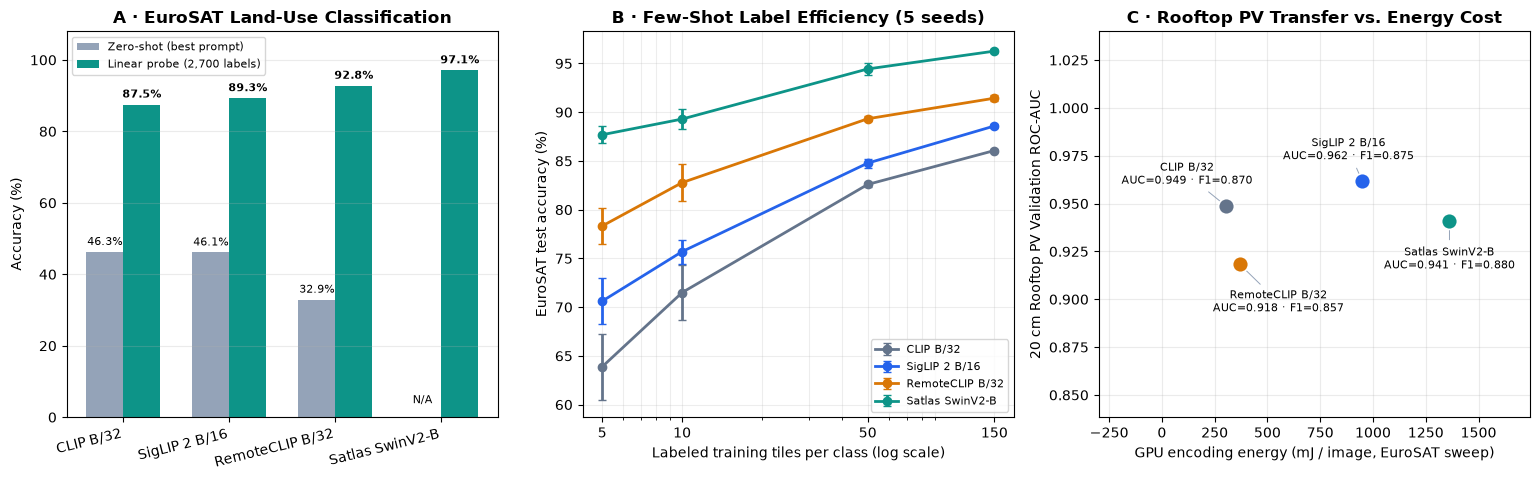

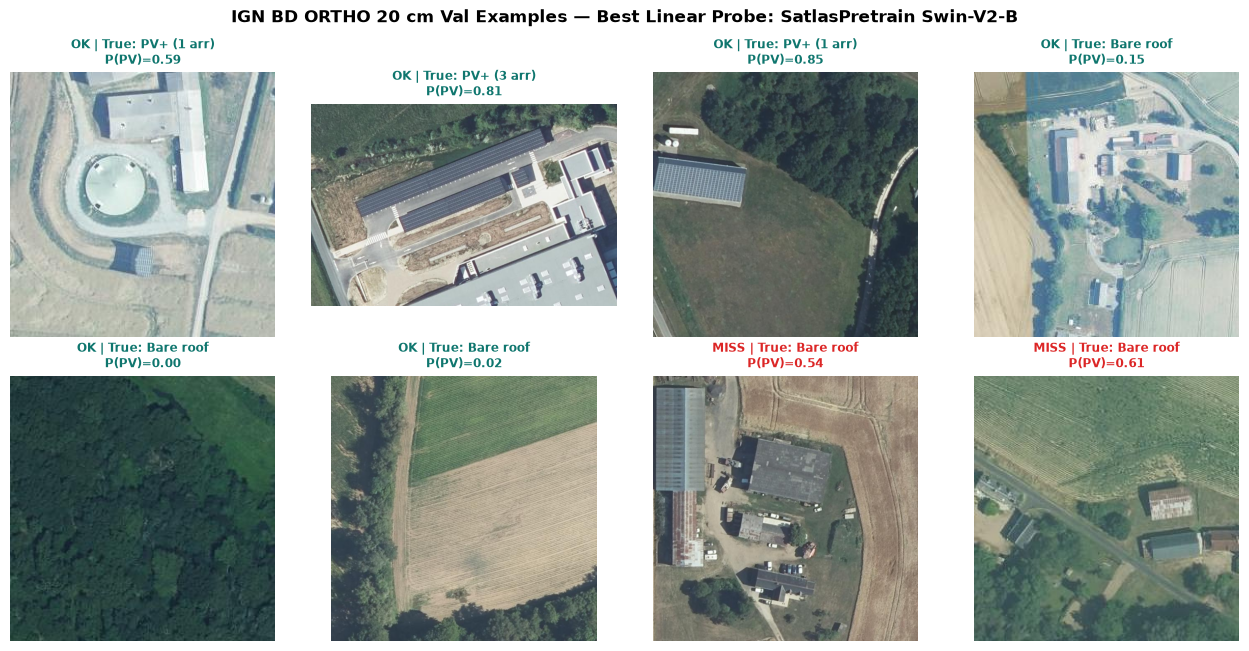

In [5]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.5, 4.9))

names_short = ["CLIP B/32", "SigLIP 2 B/16", "RemoteCLIP B/32", "Satlas SwinV2-B"]
res_list = [results[k] for k in BACKBONE_KEYS]

# Panel A: EuroSAT Zero-shot vs Probe Acc + Highway/Industrial/Res Macro
x = np.arange(len(BACKBONE_KEYS))
w = 0.35
zs_vals = [0.0 if r["eurosat_zs_acc_pct"] is None else r["eurosat_zs_acc_pct"] for r in res_list]
pr_vals = [r["eurosat_probe_acc_pct"] for r in res_list]

b_zs = ax1.bar(x - w / 2, zs_vals, width=w, color="#94a3b8", label="Zero-shot (best prompt)")
b_pr = ax1.bar(x + w / 2, pr_vals, width=w, color="#0d9488", label="Linear probe (2,700 labels)")
for i, bar in enumerate(b_zs):
    txt = "N/A" if res_list[i]["eurosat_zs_acc_pct"] is None else f"{zs_vals[i]:.1f}%"
    ax1.text(bar.get_x() + bar.get_width() / 2, max(2.0, bar.get_height()) + 1.2, txt, ha="center", va="bottom", fontsize=7.8)
for bar in b_pr:
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(names_short, rotation=14, ha="right")
ax1.set_ylim(0, 108)
ax1.set_ylabel("Accuracy (%)")
ax1.set_title("A · EuroSAT Land-Use Classification", fontweight="bold")
ax1.grid(axis="y", alpha=0.25)
ax1.legend(fontsize=8, loc="upper left")

# Panel B: Few-shot curves
shots = [5, 10, 50, 150]
colors = ["#64748b", "#2563eb", "#d97706", "#0d9488"]
for k_idx, r in enumerate(res_list):
    means = [r["few_shot"][str(s)]["mean"] for s in shots]
    stds = [r["few_shot"][str(s)]["std"] for s in shots]
    ax2.errorbar(shots, means, yerr=stds, marker="o", lw=2.0, capsize=3, color=colors[k_idx], label=names_short[k_idx])
ax2.set_xscale("log")
ax2.set_xticks(shots)
ax2.set_xticklabels([str(s) for s in shots])
ax2.set_xlabel("Labeled training tiles per class (log scale)")
ax2.set_ylabel("EuroSAT test accuracy (%)")
ax2.set_title("B · Few-Shot Label Efficiency (5 seeds)", fontweight="bold")
ax2.grid(True, which="both", alpha=0.22)
ax2.legend(fontsize=8, loc="lower right")

# Panel C: 20 cm Rooftop PV F1 & AUC vs GPU energy (mJ/img)
offsets_c = [(-28, 16), (-10, 16), (28, -34), (0, -34)]
for k_idx, r in enumerate(res_list):
    mj = r["mj_per_img_eurosat"]
    auc = r["pv_val_auc"]
    f1v = r["pv_val_f1"]
    ax3.scatter(mj, auc, s=130, color=colors[k_idx], edgecolor="white", linewidth=1.2, zorder=4)
    ax3.annotate(
        f"{names_short[k_idx]}\nAUC={auc:.3f} · F1={f1v:.3f}",
        (mj, auc),
        textcoords="offset points",
        xytext=offsets_c[k_idx],
        ha="center",
        fontsize=7.8,
        arrowprops={"arrowstyle": "-", "color": "#94a3b8", "lw": 0.7},
    )
max_mj = max(r["mj_per_img_eurosat"] for r in res_list)
ax3.set_xlabel("GPU encoding energy (mJ / image, EuroSAT sweep)")
ax3.set_ylabel("20 cm Rooftop PV Validation ROC-AUC")
ax3.set_title("C · Rooftop PV Transfer vs. Energy Cost", fontweight="bold")
ax3.set_ylim(min(r["pv_val_auc"] for r in res_list) - 0.08, 1.04)
ax3.set_xlim(-max_mj * 0.22, max_mj * 1.28)
ax3.grid(alpha=0.25)

plt.tight_layout()
fig1_path = DOCS_IMG_DIR / "m3_geospatial_benchmark.png"
fig.savefig(fig1_path, dpi=180, bbox_inches="tight")
plt.show()

# Best PV Val-F1 model qualitative grid (2x4)
best_pv_key = max(BACKBONE_KEYS, key=lambda k: (results[k]["pv_val_f1"], results[k]["pv_val_auc"]))
best_probs = results[best_pv_key]["_pv_val_probs"]
best_pred = (best_probs >= 0.5).astype(int)

pos_correct = [i for i in range(len(ign_val)) if y_pv_va[i] == 1 and best_pred[i] == 1]
neg_correct = [i for i in range(len(ign_val)) if y_pv_va[i] == 0 and best_pred[i] == 0]
errors = [i for i in range(len(ign_val)) if y_pv_va[i] != best_pred[i]]

chosen = []
for bucket, tag in [(pos_correct, "TP"), (neg_correct, "TN"), (errors, "ERR")]:
    for idx in bucket[: (4 if tag == "ERR" else 3)]:
        chosen.append((idx, tag))
chosen = chosen[:8]
# Pad if <2 errors so grid stays 8 tiles cleanly
while len(chosen) < 8:
    for idx in range(len(ign_val)):
        if idx not in [c[0] for c in chosen]:
            chosen.append((idx, "TP" if y_pv_va[idx] == 1 else "TN"))
        if len(chosen) == 8:
            break

fig2, axes2 = plt.subplots(2, 4, figsize=(13.0, 6.6))
for ax, (idx, tag) in zip(axes2.flat, chosen):
    rec = ign_val[idx]
    ax.imshow(rec["image"])
    ax.axis("off")
    status_ok = (best_pred[idx] == y_pv_va[idx])
    col = "#0f766e" if status_ok else "#dc2626"
    true_lbl = f"PV+ ({rec['n_arrays']} arr)" if rec["has_pv"] else "Bare roof"
    ax.set_title(
        f"{'OK' if status_ok else 'MISS'} | True: {true_lbl}\nP(PV)={best_probs[idx]:.2f}",
        fontsize=8.8,
        color=col,
        fontweight="bold",
    )
plt.suptitle(f"IGN BD ORTHO 20 cm Val Examples — Best Linear Probe: {results[best_pv_key]['name']}", fontweight="bold")
plt.tight_layout()
fig2_path = DOCS_IMG_DIR / "m3_rooftop_pv_examples.png"
fig2.savefig(fig2_path, dpi=180, bbox_inches="tight")
plt.show()

## 4 · Operational Summary & Export

In [6]:
profiler.stop_run()
csv_path, json_path = profiler.save()

print("Model Cards:")
display(profiler.model_card_table())

print("\nPer-Step Latency, VRAM, Power & GPU Energy:")
display(profiler.summary_table())

print("\nWhole-Notebook Energy & Grid CO2e Comparison:")
display(profiler.energy_summary_table())

print(f"Exported benchmarks/results/{json_path.name}")

Model Cards:


,Params (M),Precision,Disk (MB),Peak VRAM (GB),Min Hardware,Licence,Limits
Model,,,,,,,
CLIP ViT-B/32,151.28,float32,1214.0,1.010,GPU <= 4 GB,MIT,"224x224 px, 77 text tokens; web-photo bias"
SigLIP 2 Base (16/224),375.19,float32,1535.2,2.516,GPU <= 4 GB,Apache-2.0,"224x224 px, 64 text tokens (lowercase recommen..."
RemoteCLIP ViT-B/32,151.28,float32,605.2,0.935,GPU <= 4 GB,Unspecified on HF card,"224x224 px, 77 text tokens; tuned for remote s..."
SatlasPretrain Swin-V2-B,86.91,float32,352.7,1.633,GPU <= 4 GB,Apache-2.0,"Vision-only (no text encoder); expects [0,1] S..."



Per-Step Latency, VRAM, Power & GPU Energy:


,Time (s),Peak VRAM (GB),Avg Power (W),GPU Energy (J),mJ / item,ms / item,CO2 CH (mg),CO2 EU (mg)
Step,,,,,,,,
"1. Load EuroSAT (5,400) & IGN BD ORTHO rooftop PV (336)",3.7,0.00,56.2,210.8,NaN,NaN,1.76,13.47
"Encode 5,400 EuroSAT · CLIP ViT-B/32",10.5,1.01,156.5,1636.7,303.09,1.94,13.64,104.57
Encode 336 IGN PV · CLIP ViT-B/32,2.0,1.01,105.7,209.2,622.72,5.88,1.74,13.37
"Encode 5,400 EuroSAT · SigLIP 2 Base (16/224)",23.0,2.52,223.3,5128.9,949.80,4.25,42.74,327.68
Encode 336 IGN PV · SigLIP 2 Base (16/224),2.6,2.52,158.0,407.2,1211.94,7.66,3.39,26.02
"Encode 5,400 EuroSAT · RemoteCLIP ViT-B/32",13.6,0.94,145.5,1985.9,367.75,2.53,16.55,126.88
Encode 336 IGN PV · RemoteCLIP ViT-B/32,1.7,0.94,117.4,202.5,602.62,5.13,1.69,12.94
"Encode 5,400 EuroSAT · SatlasPretrain Swin-V2-B",31.9,1.63,230.3,7356.4,1362.30,5.92,61.30,469.99
Encode 336 IGN PV · SatlasPretrain Swin-V2-B,2.9,1.63,195.0,557.6,1659.46,8.50,4.65,35.62



Whole-Notebook Energy & Grid CO2e Comparison:


,Duration (s),GPU (Wh),"CPU + RAM (Wh, modeled)",Total (Wh),CO2 CH 30g/kWh (mg),CO2 EU 230g/kWh (mg),CO2 US 380g/kWh (mg)
Scope,,,,,,,
"Profiled steps (GPU only, NVML 50 ms)",91.9,4.9153,NaN,4.9153,147.46,1130.53,1867.83
Whole notebook (CodeCarbon offline: GPU + CPU/RAM model),137.6,4.7450,4.46,9.2050,276.15,2117.16,3497.91


Exported benchmarks/results/module3_multimodal_02_geospatial_energy_fms.json


## Key Takeaways

1. **Sentinel-2 pretraining wins EuroSAT & few-shot efficiency:** Domain-matched EO encoders extract strong land-use boundaries with tiny labeled budgets (`5–50` labels per class) compared with internet photo contrastive models.
2. **Resolution & domain alignment matter differently for rooftop PV:** 20 cm aerial roofs look nothing like 10 m Sentinel-2 tiles, so models with finer patch resolution (`ViT-B/16` in SigLIP 2) or aerial/RS contrastive training (`RemoteCLIP`) must be verified on actual high-res siting labels rather than assuming EuroSAT accuracy transfers blindly.